# AI Investment Committee

**AAI-520 Final Team Project, Group 7**<br>
**Team:** Guna Pasupathy, Mina Habib, and Michael Valderrama<br>
**Repository:** [AAI-520-Final-Project](https://github.com/ibucketbranch/AAI-520-Final-Project)

This notebook shows how our investment committee plans research, routes work,
processes news, builds Bull and Bear claims, checks those claims, and remembers
a lesson for the next run. It is a class demonstration, not financial advice.

The demo is offline. The articles and financial values are synthetic fixtures.
A scripted client stands in for a language model so the same review behavior can
be reproduced without an API key.

## 1. Agent design and workflows

The system starts with a stock symbol. A planner decides which sources to use.
Earnings, news, and market gatherers add facts to one evidence pool. The Bull
and Bear analysts make claims from that pool. The evaluator checks every cited
evidence ID and sends weak claims back for one more draft. The final run saves a
memory note that the next plan can read.

We use three workflow patterns:

1. **Routing:** each plan task goes to the matching gatherer.
2. **Prompt chaining:** news moves through ingest, clean, classify, gate,
   entity extraction, and summary steps.
3. **Evaluator-optimizer:** claims are drafted, checked, and revised when needed.

```mermaid
flowchart TD
    S[Stock symbol] --> P[Planner]
    P --> E[Earnings gatherer]
    P --> N[News gatherer]
    P --> M[Market gatherer]
    E --> POOL[(Evidence pool)]
    N --> C[News chain and gate]
    C --> POOL
    M --> POOL
    POOL --> BULL[Bull analyst]
    POOL --> BEAR[Bear analyst]
    BULL --> EV[Evaluator]
    BEAR --> EV
    EV --> V[Verdict and memo]
    EV --> MEM[Memory note]
    MEM -.-> P
```

### Shared records: code used in this section

The full notebook includes the main implementation so it can be reviewed here.

```python
class Run(BaseModel):
    """One end-to-end research run for a stock symbol.

    with_review is False for the "without the review loop" runs in the
    evaluation, so the two kinds can be told apart afterwards. memo and
    finished_at are filled in when the run completes.
    parent_run_id links a committee run to the gathering run that owns its evidence.
    """

    run_id: str = Field(default_factory=new_id)
    symbol: str
    with_review: bool = True
    parent_run_id: str | None = None
    started_at: str = Field(default_factory=now_iso)
    finished_at: str | None = None
    memo: str | None = None

class Evidence(BaseModel):
    """One fact a gatherer found. The evidence pool is a list of these.

    reference says where the fact came from (a URL, or something like
    "yfinance:AAPL:income_stmt") so a reader can check it.
    """

    evidence_id: str = Field(default_factory=new_id)
    run_id: str
    symbol: str
    source: Source
    title: str
    content: str
    as_of: str
    reference: str

class Claim(BaseModel):
    """One statement from Bull or Bear, with pointers to its evidence.

    ADR-0002 rule: every claim carries at least one evidence pointer, so
    evidence_ids cannot be empty. The evaluator fills in supported and
    reason; a claim that was sent back and rewritten comes back with
    revision + 1.
    """

    claim_id: str = Field(default_factory=new_id)
    run_id: str
    side: Side
    text: str
    evidence_ids: list[str] = Field(min_length=1)
    supported: bool | None = None
    reason: str | None = None
    revision: int = 0

class MemoryNote(BaseModel):
    """What one run learned, read by the planner at the start of the next.

    confidence is the drafting step's own estimate, 0 to 1, and open_gaps
    lists what it could not find out. Together they are the self-reflection
    record from the proposal.
    """

    note_id: str = Field(default_factory=new_id)
    run_id: str
    symbol: str
    confidence: float = Field(ge=0.0, le=1.0)
    open_gaps: list[str]
    lesson: str
    created_at: str = Field(default_factory=now_iso)
```

In [1]:
import json
import sys
from pathlib import Path
from types import SimpleNamespace

import pandas as pd
import spacy

# This works when the notebook starts from the repository root or its own folder.
ROOT = next(
    folder for folder in [Path.cwd(), *Path.cwd().parents] if (folder / "pyproject.toml").exists()
)
sys.path.insert(0, str(ROOT / "src"))

from investment_committee.agents.analyst import DraftedClaim, DraftedClaims
from investment_committee.agents.bear import draft_bear_claims
from investment_committee.agents.bull import draft_bull_claims
from investment_committee.agents.evaluator import ClaimVerdict
from investment_committee.agents.planner import build_plan
from investment_committee.config import ENV_VARS, Settings
from investment_committee.evaluation.harness import (
    plot_support_comparison,
    run_review_comparison,
)
from investment_committee.evaluation.metrics import comparison_rows, score_run
from investment_committee.models import Evidence, Run
from investment_committee.storage import open_db, save_run_with_evidence
from investment_committee.workflows.chaining import (
    ingest,
    processed_to_evidence,
    run_chain,
)
from investment_committee.workflows.evaluator_optimizer import CommitteeVerdict
from investment_committee.workflows.routing import route_plan

print("Project package loaded from the repository.")
print("This run uses local fixtures and makes no network calls.")

Project package loaded from the repository.
This run uses local fixtures and makes no network calls.


The scripted client below returns fixed structured responses. It is only used
for the offline class demo. The production path uses the same functions with an
OpenAI client when a key is available.

In [2]:
class ScriptedResponses:
    def __init__(self, drafts, verdicts, decisions):
        self.drafts = list(drafts)
        self.verdicts = list(verdicts)
        self.decisions = list(decisions)

    def parse(self, *, model, instructions, input, text_format):
        if text_format is DraftedClaims:
            result = self.drafts.pop(0)
        elif text_format is ClaimVerdict:
            result = self.verdicts.pop(0)
        elif text_format is CommitteeVerdict:
            result = self.decisions.pop(0)
        else:
            raise ValueError(f"Unexpected response type: {text_format}")

        return SimpleNamespace(
            output_parsed=result,
            model="offline-scripted-model",
            usage=SimpleNamespace(input_tokens=10, output_tokens=5),
        )


class ScriptedClient:
    def __init__(self, drafts, verdicts, decisions):
        self.responses = ScriptedResponses(drafts, verdicts, decisions)


def drafted_claim(evidence_id, text):
    return DraftedClaims(claims=[DraftedClaim(text=text, evidence_ids=[evidence_id])])


def make_demo_client():
    # The reviewed arm rejects one Bear draft and replaces it in round two.
    # The baseline arm stops after the same first-round rejection.
    drafts = [
        drafted_claim("ev-001", "Revenue growth supports the Bull case."),
        drafted_claim("missing-evidence", "Profit collapsed in the quarter."),
        drafted_claim("ev-002", "Valuation still depends on continued EPS growth."),
        drafted_claim("ev-001", "Revenue growth supports the Bull case."),
        drafted_claim("missing-evidence", "Profit collapsed in the quarter."),
    ]
    verdicts = [
        ClaimVerdict(supported=True, reason="The revenue evidence supports it."),
        ClaimVerdict(supported=True, reason="The revenue evidence still supports it."),
        ClaimVerdict(supported=True, reason="The EPS evidence supports the revision."),
        ClaimVerdict(supported=True, reason="The revenue evidence supports it."),
    ]
    decisions = [
        CommitteeVerdict(side="none", reason="Both sides have supported points."),
        CommitteeVerdict(side="bull", reason="Only the Bull claim survived."),
    ]
    return ScriptedClient(drafts, verdicts, decisions)


demo_settings = Settings(
    values={name: "offline-demo" if name == "OPENAI_API_KEY" else None for name in ENV_VARS}
)

## 2. Planner and dynamic tool use

The planner returns an ordered list of sources. The router reads that list and
calls the matching gatherer. For this offline run, each gatherer reads from the
committed evidence fixture instead of calling a live service.

### Planner and router: code used in this section

The full notebook includes the main implementation so it can be reviewed here.

```python
def build_plan(symbol: str, previous_note: MemoryNote | None = None) -> ResearchPlan:
    """Create the deterministic v1 research plan.

    A source mentioned in the previous run's open gaps moves to the front of
    the plan. This makes the memory handoff observable while keeping the
    Module 4 walking skeleton independent of an LLM.

    Args:
        symbol: Stock symbol to research.
        previous_note: Most recent note for this symbol, when one exists.

    Returns:
        An ordered plan containing earnings, news, and market tasks.

    Raises:
        ValueError: If the symbol is invalid or the note belongs to another
            symbol.
    """
    normalized = normalize_symbol(symbol)
    if previous_note is not None and normalize_symbol(previous_note.symbol) != normalized:
        raise ValueError("The memory note belongs to a different stock symbol.")

    gaps = [gap.casefold() for gap in previous_note.open_gaps] if previous_note else []
    prioritized = [source for source in _SOURCE_ORDER if any(source in gap for gap in gaps)]
    ordered = prioritized + [source for source in _SOURCE_ORDER if source not in prioritized]

    tasks = [
        ResearchTask(
            source=source,
            reason=(
                f"Revisit the {source} gap reported by the previous run."
                if source in prioritized
                else _REASONS[source]
            ),
        )
        for source in ordered
    ]
    return ResearchPlan(
        symbol=normalized,
        tasks=tasks,
        memory_lesson=previous_note.lesson if previous_note else None,
    )

def route_plan(
    run: Run,
    plan: ResearchPlan,
    gatherers: Mapping[Source, Gatherer] | None = None,
) -> dict[Source, GathererResult]:
    """Dispatch each plan task to its source-specific gatherer.

    The news result is a list of RawArticle objects for Mina's chain. Market
    and earnings results are already Evidence. The walking-skeleton
    orchestrator can therefore show the handoff without coupling the router
    to news preprocessing.

    Args:
        run: Research run passed to every gatherer.
        plan: Ordered tasks produced by the planner.
        gatherers: Optional injected handlers; defaults to the live tools.

    Returns:
        Results keyed by source, preserving the plan's insertion order.

    Raises:
        ValueError: If the run and plan symbols differ or a source is listed
            more than once.
        KeyError: If no gatherer was supplied for a planned source.
    """
    if normalize_symbol(run.symbol) != plan.symbol:
        raise ValueError("The research run and plan use different stock symbols.")

    routed_run = run.model_copy(update={"symbol": plan.symbol})
    handlers = default_gatherers() if gatherers is None else gatherers
    results: dict[Source, GathererResult] = {}
    for task in plan.tasks:
        if task.source in results:
            raise ValueError(f"The plan contains duplicate {task.source} tasks.")
        handler = handlers.get(task.source)
        if handler is None:
            raise KeyError(f"No gatherer configured for {task.source}.")
        results[task.source] = handler(routed_run)
    return results
```

In [3]:
fixture = json.loads((ROOT / "tests/fixtures/sample_evidence.json").read_text())
fixture_evidence = [Evidence(**item) for item in fixture["evidence"]]

plan = build_plan("AAPL")
routing_run = Run(symbol="AAPL")


def fixture_gatherer(source):
    def gather(run):
        return [
            item.model_copy(update={"run_id": run.run_id})
            for item in fixture_evidence
            if item.source == source
        ]

    return gather


gatherers = {source: fixture_gatherer(source) for source in ("earnings", "news", "market")}
routed = route_plan(routing_run, plan, gatherers)

display(pd.DataFrame([task.model_dump() for task in plan.tasks]))
display(
    pd.DataFrame(
        [{"source": source, "rows returned": len(items)} for source, items in routed.items()]
    )
)

,source,reason
0,earnings,Collect the latest quarterly performance.
1,news,Collect recent events that may affect the comp...
2,market,Collect recent price history and market indica...


,source,rows returned
0,earnings,2
1,news,1
2,market,1


## 3. News chain: ingest, preprocess, classify, extract, summarize

The news chain keeps each step visible. The classification gate only promotes
earnings, product, legal, or market articles into the shared evidence pool.
General articles remain visible in the results but do not become evidence.

### News chain: code used in this section

The full notebook includes the main implementation so it can be reviewed here.

```python
def ingest(path: str | Path) -> list[RawArticle]:
    """Load articles from a JSON file of saved samples.

    Args:
        path: A JSON file holding a list of article objects with the
            RawArticle fields.

    Returns:
        The articles in file order, validated into RawArticle models.

    Raises:
        FileNotFoundError: If the file does not exist.
        pydantic.ValidationError: If an object is missing a required field.
    """
    records = json.loads(Path(path).read_text(encoding="utf-8"))
    return [RawArticle(**record) for record in records]

def clean_text(text: str) -> str:
    """Return one article text cleaned for the downstream stages.

    Four edits, in order: drop HTML tags, map typographic characters to their
    ASCII equivalents, NFKD-normalize and drop what still does not encode
    (accented letters fall back to their base letter), and collapse
    whitespace runs.

    Args:
        text: Raw article text, possibly containing HTML and Unicode
            typography.

    Returns:
        Plain ASCII text with single spaces.
    """
    text = _HTML_TAG.sub(" ", text)
    for bad, good in _ASCII_REPLACEMENTS.items():
        text = text.replace(bad, good)
    text = unicodedata.normalize("NFKD", text)
    text = text.encode("ascii", errors="ignore").decode("ascii")
    return " ".join(text.split())

def preprocess(articles: list[RawArticle]) -> list[tuple[RawArticle, str]]:
    """Clean every article and drop exact duplicates and empty bodies.

    Duplicates are detected on the cleaned, lowercased title plus body, so
    the same wire story picked up twice with different whitespace or HTML
    still counts as one.

    Args:
        articles: Ingested articles.

    Returns:
        (article, clean_text) pairs, first occurrence kept, input order
        preserved.
    """
    seen: set[str] = set()
    kept: list[tuple[RawArticle, str]] = []
    for article in articles:
        cleaned = clean_text(article.body)
        if not cleaned:
            continue
        fingerprint = (clean_text(article.title) + " " + cleaned).lower()
        if fingerprint in seen:
            continue
        seen.add(fingerprint)
        kept.append((article, cleaned))
    return kept

def classify(text: str) -> str:
    """Assign one coarse category to a cleaned article text.

    Placeholder implementation: the first category whose keyword list
    matches, in _CATEGORY_KEYWORDS order, with "general" as the fallback.
    Scheduled to become a model-based classifier once the course covers it;
    the signature stays.

    Args:
        text: Cleaned article text from preprocess().

    Returns:
        One of the _CATEGORY_KEYWORDS categories or "general".
    """
    lowered = text.lower()
    for category, keywords in _CATEGORY_KEYWORDS.items():
        if any(keyword in lowered for keyword in keywords):
            return category
    return "general"

def classification_gate(category: str) -> tuple[bool, str]:
    """Decide whether a classified article may continue through the chain.

    The gate sits immediately after ``classify()``.  Known investment-driver
    categories continue; ``general`` and unknown labels are stopped.  The
    decision and reason are returned together so downstream code can explain
    why an article was or was not promoted to Evidence.

    Args:
        category: Label returned by ``classify()``.

    Returns:
        ``(accepted, reason)``.  Accepted articles get a short audit reason;
        rejected articles identify the category that failed the gate.
    """
    normalized = category.strip().casefold()
    if normalized in _GATE_CATEGORIES:
        return True, f"accepted classification: {normalized}"
    return False, f"rejected classification: {normalized or 'empty'}"

def extract(text: str, nlp: Language) -> list[Entity]:
    """Find named entities in a cleaned article text.

    Args:
        text: Cleaned article text from preprocess().
        nlp: A spaCy pipeline with an entity recognizer (load_nlp() for the
            real one; tests pass a blank pipeline with an entity ruler).

    Returns:
        Entities in document order, with character offsets into text.
    """
    doc = nlp(text)
    return [
        Entity(text=ent.text, label=ent.label_, start=ent.start_char, end=ent.end_char)
        for ent in doc.ents
    ]

def summarize(text: str, max_sentences: int = 2) -> str:
    """Return a short extractive summary of a cleaned article text.

    Placeholder implementation: the first max_sentences sentences, split on
    sentence-ending punctuation. Scheduled to become a model-based
    summarizer later in the course; the signature stays.

    Args:
        text: Cleaned article text from preprocess().
        max_sentences: How many leading sentences to keep.

    Returns:
        The leading sentences joined with single spaces.
    """
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return " ".join(sentences[:max_sentences]).strip()

def run_chain(articles: list[RawArticle], nlp: Language) -> list[ProcessedArticle]:
    """Run ingest output through preprocess, classify, gate, extract, summarize.

    The gate is evaluated immediately after classification.  For backwards
    compatibility with the Sep 15 chain, NER and summarization still run for
    every surviving preprocessed article; the gate controls promotion into the
    shared Evidence pool rather than deleting an article from the chain output.

    Args:
        articles: Ingested articles from the live news tool or a fixture.
        nlp: The spaCy pipeline used by ``extract()``.

    Returns:
        One ``ProcessedArticle`` for every article that survives preprocessing.
        Rejected articles remain in the result with ``accepted=False`` so the
        evaluation code can measure the gate instead of silently losing them.
    """
    processed: list[ProcessedArticle] = []
    for article, cleaned in preprocess(articles):
        category = classify(cleaned)
        accepted, gate_reason = classification_gate(category)

        # The gate sits after classification.  We still finish the original
        # chain for compatibility and auditability; processed_to_evidence()
        # enforces the gate at the shared-model boundary.
        entities = extract(cleaned, nlp)
        summary = summarize(cleaned)

        processed.append(
            ProcessedArticle(
                article=article,
                clean_text=cleaned,
                category=category,
                accepted=accepted,
                gate_reason=gate_reason,
                entities=entities,
                summary=summary,
            )
        )
    return processed

def processed_to_evidence(run: Run, articles: list[ProcessedArticle]) -> list[Evidence]:
    """Convert accepted news-chain output into the project's shared Evidence model.

    This is the ownership boundary between the news chain and the rest of the
    investment committee.  The chain owns article processing; the shared
    ``Evidence`` model is the contract consumed by Bull, Bear, and Evaluator.

    Each accepted article becomes one evidence item.  The evidence content is
    the chain's extractive summary, while the original title and source URL or
    provider identifier remain available in the title/reference fields.

    Args:
        run: Shared run record that owns the evidence.
        articles: Output from ``run_chain()``.

    Returns:
        Evidence records for accepted articles only.
    """
    evidence: list[Evidence] = []
    for item in articles:
        if not item.accepted:
            continue

        evidence.append(
            Evidence(
                run_id=run.run_id,
                symbol=run.symbol,
                source="news",
                title=item.article.title,
                content=item.summary or item.clean_text,
                as_of=item.article.published,
                reference=item.article.source,
            )
        )
    return evidence
```

In [4]:
articles = [
    article
    for article in ingest(ROOT / "tests/fixtures/sample_articles.json")
    if article.symbol == "AAPL"
]

nlp = spacy.blank("en")
ruler = nlp.add_pipe("entity_ruler")
ruler.add_patterns(
    [
        {"label": "ORG", "pattern": "Apple"},
        {"label": "PERSON", "pattern": "Tim Cook"},
    ]
)

processed_news = run_chain(articles, nlp)
news_run = Run(symbol="AAPL")
news_evidence = processed_to_evidence(news_run, processed_news)

display(
    pd.DataFrame(
        [
            {
                "title": item.article.title,
                "category": item.category,
                "accepted": item.accepted,
                "entities": ", ".join(entity.text for entity in item.entities),
                "summary": item.summary,
            }
            for item in processed_news
        ]
    )
)
print(f"Promoted {len(news_evidence)} article(s) into Evidence rows.")

,title,category,accepted,entities,summary
0,Apple beats quarterly earnings expectations,earnings,True,"Apple, Tim Cook",Apple reported quarterly revenue of $91.2 bill...
1,Apple unveils new on-device translation feature,product,True,Apple,"At a press event in Cupertino, Apple announced..."


Promoted 2 article(s) into Evidence rows.


## 4. Bull and Bear over the evidence pool

Both analysts use the same evidence records. Every claim must list at least one
evidence ID. The simple template path below works without a model and makes the
citation handoff easy to inspect.

### Bull and Bear fallback: code used in this section

The full notebook includes the main implementation so it can be reviewed here.

```python
def draft_bull_claims(evidence: list[Evidence]) -> list[Claim]:
    """Draft the optimistic case: one templated claim per evidence item.

    Args:
        evidence: The run's evidence pool, any mix of sources.

    Returns:
        Claims with side "bull", each pointing at the one evidence item it
        restates. The template reads the item's title as a reason for
        optimism; the model path argues instead of restating.
    """
    claims: list[Claim] = []
    for item in evidence:
        claims.append(
            Claim(
                run_id=item.run_id,
                side="bull",
                text=f"Positive signal for {item.symbol}: {item.title}.",
                evidence_ids=[item.evidence_id],
            )
        )
    return claims

def draft_bear_claims(evidence: list[Evidence]) -> list[Claim]:
    """Draft the pessimistic case: one templated claim per evidence item.

    Args:
        evidence: The run's evidence pool, any mix of sources.

    Returns:
        Claims with side "bear", each pointing at the one evidence item it
        restates. The template reads the item's title as a risk; the model
        path argues instead of restating.
    """
    claims: list[Claim] = []
    for item in evidence:
        claims.append(
            Claim(
                run_id=item.run_id,
                side="bear",
                text=f"Risk signal for {item.symbol}: {item.title}.",
                evidence_ids=[item.evidence_id],
            )
        )
    return claims
```

In [5]:
# Leave out market evidence on purpose so the memory section has a real gap.
parent = Run(**fixture["run"])
evidence = [item for item in fixture_evidence if item.source != "market"]

bull_claims = draft_bull_claims(evidence)
bear_claims = draft_bear_claims(evidence)
display(
    pd.DataFrame(
        [
            {
                "side": claim.side,
                "claim": claim.text,
                "evidence IDs": ", ".join(claim.evidence_ids),
            }
            for claim in bull_claims + bear_claims
        ]
    )
)

,side,claim,evidence IDs
0,bull,Positive signal for AAPL: Quarterly revenue.,ev-001
1,bull,Positive signal for AAPL: Diluted EPS.,ev-002
2,bull,Positive signal for AAPL: Wearables line refre...,ev-003
3,bear,Risk signal for AAPL: Quarterly revenue.,ev-001
4,bear,Risk signal for AAPL: Diluted EPS.,ev-002
5,bear,Risk signal for AAPL: Wearables line refresh a...,ev-003


## 5. Evaluator-optimizer loop and verdict

We save one parent gathering run, then let both committee arms point to its
evidence. In the reviewed arm, the first Bear claim cites a missing ID. The free
citation gate rejects it, the Bear drafts a grounded replacement, and the second
round checks the replacement. The baseline arm stops after round one.

### Evaluator-optimizer loop: code used in this section

The full notebook includes the main implementation so it can be reviewed here.

```python
def evaluate_claims(claims: list[Claim], evidence: list[Evidence]) -> list[Claim]:
    """Fill in supported and reason for every claim.

    Args:
        claims: Bull and Bear claims, evidence_ids populated.
        evidence: The run's evidence pool the claims cite into.

    Returns:
        The same claims with supported set, and reason set on the
        unsupported ones so the workflow can send them back.
    """
    pool_ids = {item.evidence_id for item in evidence}
    checked: list[Claim] = []
    for claim in claims:
        missing = [eid for eid in claim.evidence_ids if eid not in pool_ids]
        if missing:
            checked.append(
                claim.model_copy(
                    update={
                        "supported": False,
                        "reason": "cites evidence not in the pool: " + ", ".join(missing),
                    }
                )
            )
        else:
            checked.append(claim.model_copy(update={"supported": True}))
    return checked

def run_committee(
    run: Run,
    evidence: list[Evidence],
    settings: Settings | None = None,
    *,
    provider: AnalystProvider = "openai",
    max_rounds: int = 2,
    model: str | None = None,
    client: Any | None = None,
) -> CommitteeResult:
    """Deliberate one run: draft, evaluate, refine, decide, reflect.

    Args:
        run: The run row; run.with_review False skips refinement so the
            with/without comparison flips exactly one variable.
        evidence: The run's evidence pool.
        settings: Environment snapshot; loaded from the environment when
            None.
        provider: "openai" for the model path with template fallback,
            "template" to never try the model.
        max_rounds: Evaluation rounds ceiling, at least 1.
        model: Model override for every call.
        client: Injected OpenAI-compatible client for tests.

    Returns:
        The full deliberation record; nothing is persisted here.
    """
    current_settings = settings or load_settings()
    evaluator_provider: Literal["openai", "rules"] = "rules" if provider == "template" else "openai"
    calls: list[ModelCall] = []
    fallbacks: dict[str, str] = {}
    dropped: list[str] = []
    all_claims: list[Claim] = []

    def drafted(result: DraftingResult, stage: str) -> list[Claim]:
        # The drafting engine stamps rows with the evidence pool's run_id,
        # which is the parent's when this run argues from a parent pool, so
        # everything is re-stamped to this deliberation before it spreads
        # (the evaluator and the verdict inherit run_id from the claims).
        if result.model_call is not None:
            calls.append(result.model_call.model_copy(update={"run_id": run.run_id}))
        if result.fallback_reason is not None:
            fallbacks[stage] = result.fallback_reason
        dropped.extend(eid for eid in result.dropped_ids if eid not in dropped)
        return [claim.model_copy(update={"run_id": run.run_id}) for claim in result.claims]

    bull = drafted(
        draft_bull_claims_model(
            evidence, current_settings, provider=provider, model=model, client=client
        ),
        "bull",
    )
    bear = drafted(
        draft_bear_claims_model(
            evidence, current_settings, provider=provider, model=model, client=client
        ),
        "bear",
    )

    rounds = 0
    current = bull + bear
    while True:
        rounds += 1
        evaluation = evaluate_claims_model(
            current,
            evidence,
            current_settings,
            provider=evaluator_provider,
            model=model,
            client=client,
        )
        calls.extend(evaluation.model_calls)
        if evaluation.fallback_reason is not None:
            fallbacks[f"evaluator round {rounds}"] = evaluation.fallback_reason
        current = evaluation.claims
        all_claims.extend(current)

        unsupported = [claim for claim in current if claim.supported is False]
        if not run.with_review or not unsupported or rounds >= max_rounds:
            break

        kept = [claim for claim in current if claim.supported]
        redrafted: list[Claim] = []
        for side, draft_side in (
            ("bull", draft_bull_claims_model),
            ("bear", draft_bear_claims_model),
        ):
            rejected = [claim for claim in unsupported if claim.side == side]
            side_kept = [claim for claim in kept if claim.side == side]
            if not rejected:
                redrafted.extend(side_kept)
                continue
            result = draft_side(
                evidence,
                current_settings,
                provider=provider,
                revise=rejected,
                keep=side_kept,
                revision=rounds,
                model=model,
                client=client,
            )
            replacements = _without_repeats(drafted(result, f"{side} round {rounds}"), side_kept)
            redrafted.extend(replacements)
            redrafted.extend(side_kept)
        current = redrafted

    if provider == "template":
        verdict: Verdict = "none"
        verdict_reason = "no model available"
        verdict_call: ModelCall | None = None
    else:
        verdict, verdict_reason, verdict_call = _decide(
            current, evidence, current_settings, model, client
        )
    if verdict_call is not None:
        calls.append(verdict_call)
    elif provider != "template" and verdict == "none":
        fallbacks.setdefault("verdict", verdict_reason)

    confidence, gaps = reflect(current, evidence)
    note = MemoryNote(
        run_id=run.run_id,
        symbol=run.symbol,
        confidence=confidence,
        open_gaps=gaps,
        lesson=f"Verdict {verdict} after {rounds} round(s): {verdict_reason}",
    )
    memo = _memo(verdict, verdict_reason, current, rounds)
    return CommitteeResult(
        run=run,
        claims=current,
        all_claims=all_claims,
        verdict=verdict,
        verdict_reason=verdict_reason,
        memo=memo,
        note=note,
        model_calls=calls,
        rounds=rounds,
        dropped_ids=dropped,
        fallbacks=fallbacks,
    )
```

In [6]:
conn = open_db(":memory:")
save_run_with_evidence(conn, parent, evidence)

comparison = run_review_comparison(
    conn,
    parent.run_id,
    demo_settings,
    client=make_demo_client(),
    model="offline-scripted-model",
)

reviewed = comparison.with_review
history = pd.DataFrame(
    [
        {
            "side": claim.side,
            "revision": claim.revision,
            "supported": claim.supported,
            "reason": claim.reason,
            "claim": claim.text,
            "evidence IDs": ", ".join(claim.evidence_ids),
        }
        for claim in reviewed.all_claims
    ]
)
display(history)
print(reviewed.memo)

,side,revision,supported,reason,claim,evidence IDs
0,bull,0,True,The revenue evidence supports it.,Revenue growth supports the Bull case.,ev-001
1,bear,0,False,cites evidence not in the pool: missing-evidence,Profit collapsed in the quarter.,missing-evidence
2,bull,0,True,The revenue evidence still supports it.,Revenue growth supports the Bull case.,ev-001
3,bear,1,True,The EPS evidence supports the revision.,Valuation still depends on continued EPS growth.,ev-002


Verdict: none. Both sides have supported points.
Diagnostics: 1 supported bull claim(s), 1 supported bear claim(s) after 2 round(s); counts informed nothing.
- [bull] Revenue growth supports the Bull case. (evidence: ev-001)
- [bear] Valuation still depends on continued EPS growth. (evidence: ev-002)


## 6. Memory across runs

Reflection writes a confidence value, open gaps, and a short lesson. Our parent
pool intentionally has no market evidence, so the reviewed run records that gap.
The next rule-based plan moves market research to the first position.

In [7]:
note = reviewed.note
first_plan = build_plan("AAPL")
next_plan = build_plan("AAPL", note)

print("Saved lesson:", note.lesson)
print("Open gaps:", note.open_gaps)
display(
    pd.DataFrame(
        {
            "first plan": [task.source for task in first_plan.tasks],
            "next plan": [task.source for task in next_plan.tasks],
        }
    )
)

Saved lesson: Verdict none after 2 round(s): Both sides have supported points.
Open gaps: ['no market evidence in the pool']


,first plan,next plan
0,earnings,market
1,news,earnings
2,market,news


## 7. Evaluation and iteration: with review vs. without review

Both arms use the same parent evidence. The only setting that changes is
`with_review`. The table is read back from SQLite instead of being built from
temporary Python objects. Rejected drafts count every draft that failed at any
point, including a draft that was later replaced.

### A/B harness and metrics: code used in this section

The full notebook includes the main implementation so it can be reviewed here.

```python
def run_review_comparison(
    conn: sqlite3.Connection,
    parent_run_id: str,
    settings: Settings | None = None,
    *,
    provider: AnalystProvider = "openai",
    max_rounds: int = 2,
    model: str | None = None,
    client: Any | None = None,
) -> ReviewComparison:
    """Deliberate one gathering run twice: with the review loop, then without.

    Args:
        conn: An open connection from open_db().
        parent_run_id: The gathering run whose evidence both arms argue from.
        settings: Loaded settings, or None to read the environment.
        provider: Analyst provider, "openai" or the offline "template".
        max_rounds: Round cap for the with-review arm.
        model: Model override, or None for the configured default.
        client: Injected API client, mainly for offline tests.

    Returns:
        Both deliberations; each one is already persisted by the time this
        returns, so the metrics can read them back from the same database.

    Raises:
        ValueError: If the parent run is not in this database.
    """
    parent = load_run(conn, parent_run_id)
    if parent is None:
        raise ValueError(f"run {parent_run_id!r} is not in this database; gather or seed it first")
    results: dict[bool, CommitteeResult] = {}
    for with_review in (True, False):
        run = Run(symbol=parent.symbol, with_review=with_review, parent_run_id=parent_run_id)
        save_run(conn, run)
        results[with_review] = run_committee_from_storage(
            conn,
            run.run_id,
            settings,
            provider=provider,
            max_rounds=max_rounds,
            model=model,
            client=client,
        )
    return ReviewComparison(
        parent_run_id=parent_run_id,
        with_review=results[True],
        without_review=results[False],
    )

def score_run(conn: sqlite3.Connection, run_id: str) -> RunScore:
    """Score one finished committee run from storage.

    Args:
        conn: An open connection from open_db().
        run_id: A committee run that finished and wrote its memo.

    Returns:
        The run's scorecard.

    Raises:
        ValueError: If the run is missing, never finished, or its memo does
            not carry the committee's verdict line.
    """
    run = load_run(conn, run_id)
    if run is None:
        raise ValueError(f"run {run_id!r} is not in this database")
    if run.memo is None:
        raise ValueError(f"run {run_id!r} never finished; there is no memo to score")
    claims = load_claims(conn, run_id)
    calls = load_model_calls(conn, run_id)
    return RunScore(
        run_id=run_id,
        symbol=run.symbol,
        with_review=run.with_review,
        verdict=_verdict_from_memo(run_id, run.memo),
        rounds=_rounds_from_memo(run_id, run.memo),
        claims_supported=sum(1 for claim in claims if claim.supported),
        claims_rejected=sum(1 for claim in claims if claim.supported is False),
        model_calls=len(calls),
        prompt_tokens=sum(call.prompt_tokens for call in calls),
        completion_tokens=sum(call.completion_tokens for call in calls),
    )

def comparison_rows(conn: sqlite3.Connection, run_ids: Sequence[str]) -> list[dict[str, object]]:
    """Build the comparison table, one row per run, ready for a DataFrame.

    Args:
        conn: An open connection from open_db().
        run_ids: The finished runs to compare, in display order.

    Returns:
        Plain dict rows so the notebook can pandas.DataFrame() them.
    """
    rows: list[dict[str, object]] = []
    for run_id in run_ids:
        score = score_run(conn, run_id)
        rows.append(
            {
                "symbol": score.symbol,
                "review loop": "on" if score.with_review else "off",
                "verdict": score.verdict,
                "rounds": score.rounds,
                "supported claims": score.claims_supported,
                "rejected drafts": score.claims_rejected,
                "model calls": score.model_calls,
                "tokens": score.prompt_tokens + score.completion_tokens,
                "run id": score.run_id,
            }
        )
    return rows

def plot_support_comparison(scores: Sequence[RunScore]) -> tuple[Figure, Axes]:
    """Plot supported claims and rejected drafts from stored committee runs."""
    import matplotlib.pyplot as plt

    labels = [
        f"{score.symbol}\n{'with review' if score.with_review else 'without review'}"
        for score in scores
    ]
    supported = [score.claims_supported for score in scores]
    rejected = [score.claims_rejected for score in scores]

    figure, axis = plt.subplots(figsize=(10, 5))
    positions = list(range(len(scores)))
    width = 0.38
    axis.bar([p - width / 2 for p in positions], supported, width, label="Supported")
    axis.bar([p + width / 2 for p in positions], rejected, width, label="Rejected drafts")
    axis.set_xticks(positions, labels)
    axis.set_ylabel("Claim count")
    axis.set_title("Claim support with and without review")
    axis.legend()
    figure.tight_layout()
    return figure, axis
```

,symbol,review loop,verdict,rounds,supported claims,rejected drafts,model calls,tokens,run id
0,AAPL,on,none,2,2,1,7,105,0174ee2da3f0
1,AAPL,off,bull,1,1,1,4,60,708b8327ba1d


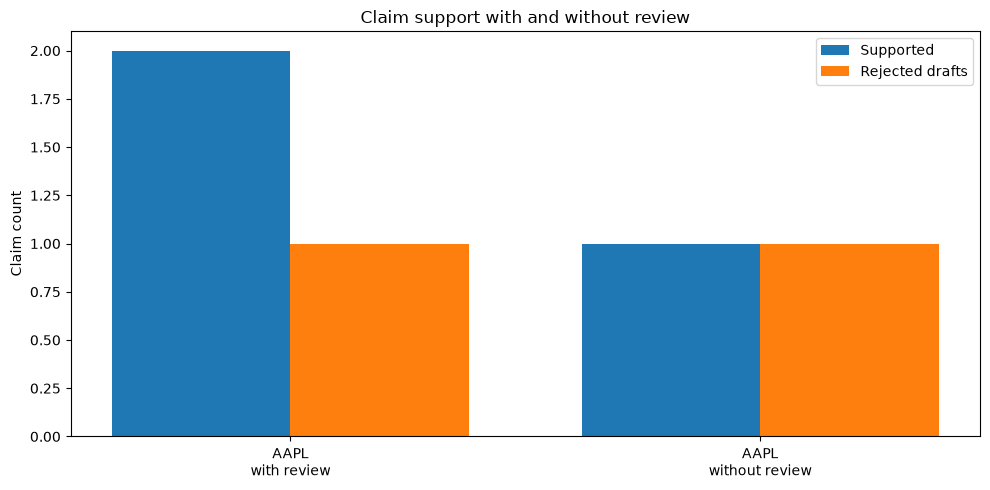

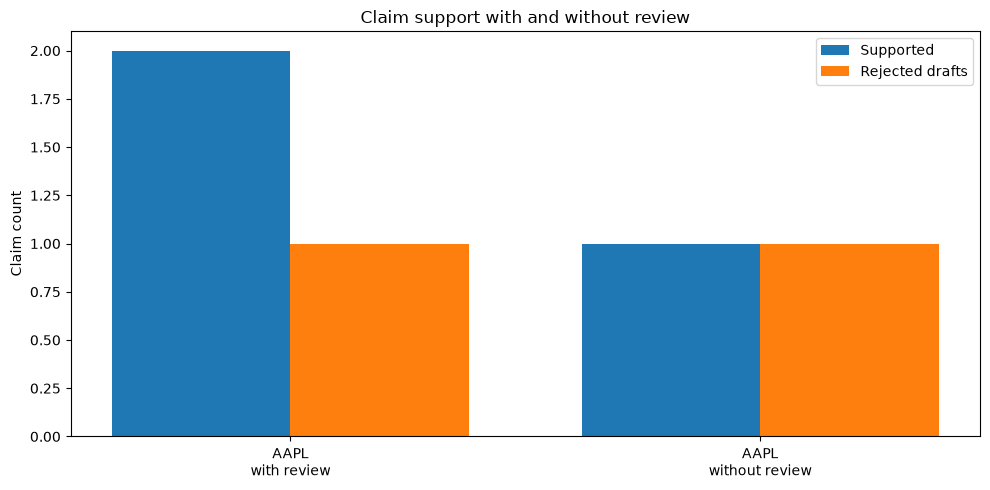

In [8]:
run_ids = [reviewed.run.run_id, comparison.without_review.run.run_id]
rows = comparison_rows(conn, run_ids)
display(pd.DataFrame(rows))

scores = [score_run(conn, run_id) for run_id in run_ids]
figure, axis = plot_support_comparison(scores)
display(figure)

In this offline example, review adds a second round and replaces the unsupported
Bear draft with a supported claim. The no-review arm keeps the rejection and
stops after one round. This is the behavior we wanted the A/B test to measure.

The result does **not** show that the system predicts stock returns. It only shows
that the review loop can improve citation support on a controlled example.

## 8. Conclusions

The project works best when every step uses the same small record types. The
shared Evidence model lets market data, earnings data, and approved news flow
into the same Bull, Bear, and evaluator code. SQLite also makes the comparison
easier to audit because claims, calls, notes, and memos stay attached to a run.

The main limitations are the use of synthetic fixtures in the offline demo,
unstable public data services, and the fact that model judgments can change.
With more time, we would test more symbols, add SEC filings, and compare the
evaluator with a second model family.

## 9. AI tool disclosures

These are draft disclosures. Each team member should confirm the tool version
and wording before submission.

**Guna Pasupathy.** I used Codex to help review the planner integration, resolve
Git conflicts, and assemble this notebook. I checked the function calls, ran the
offline notebook, and verified the results against the tests. The design choices
and conclusions reflect my own understanding of the project.

**Michael Valderrama.** I used Claude to help draft and review parts of the Bull,
Bear, evaluator, and evaluation harness code. I revised the code, added offline
tests, and checked the final behavior. Before submission, I will add the exact
Claude model version I used. The design choices and conclusions reflect my own
understanding of the project.

**Mina Habib.** Mina will add a first-person paragraph naming the AI tools and
versions she used for the news chain, what the tools helped with, and what she
personally checked. The final paragraph will state that the methods and
conclusions reflect her own understanding.

## References

Anthropic. (2024). *Building effective agents*.
https://www.anthropic.com/research/building-effective-agents

Du, Y., Li, S., Torralba, A., Tenenbaum, J. B., & Mordatch, I. (2023).
*Improving factuality and reasoning in language models through multiagent
debate*. International Conference on Machine Learning.
https://arxiv.org/abs/2305.14325

Panickssery, A., Bowman, S. R., & Feng, S. (2024). *LLM evaluators recognize
and favor their own generations*. Advances in Neural Information Processing
Systems. https://arxiv.org/abs/2404.13076

Xiao, Y., Sun, E., Luo, D., & Wang, W. (2024). *TradingAgents: Multi-agents
LLM financial trading framework*. https://arxiv.org/abs/2412.20138